# Local pipeline: Feast + MLflow + CodeCarbon
Predict a CrossFit athlete's deadlift with a random forest.
We build 2 versions of the features and train with 2 sets of hyperparameters, so 4 experiments in total.

In [25]:
%matplotlib inline
import os
from datetime import datetime

import matplotlib.pyplot as plt
import mlflow
import pandas as pd
from codecarbon import OfflineEmissionsTracker
from feast import Entity, FeatureService, FeatureStore, FeatureView, Field, FileSource
from feast.types import Float64
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

os.makedirs('feature_repo/data', exist_ok=True)

## 1. Load and clean the data

In [26]:
df = pd.read_csv('data/athletes.csv')

# keep only the columns we need and drop rows with missing values
cols = ['athlete_id', 'gender', 'age', 'height', 'weight', 'candj', 'snatch', 'backsq', 'deadlift']
df = df[cols].dropna().drop_duplicates('athlete_id')
df = df[df['gender'].isin(['Male', 'Female'])]

# remove unrealistic values
df = df[df['age'].between(14, 80) & df['height'].between(48, 84) & df['weight'].between(90, 400)]
df = df[df['candj'].between(40, 600) & df['snatch'].between(30, 500)]
df = df[df['backsq'].between(50, 800) & df['deadlift'].between(80, 900)]
df['athlete_id'] = df['athlete_id'].astype(int)

print(len(df), 'athletes after cleaning')

70227 athletes after cleaning


## 2. Create two versions of the features
- **v1:** body measurements only
- **v2:** v1 plus the other lifts and each lift divided by bodyweight

In [27]:
v1 = df[['athlete_id', 'age', 'height', 'weight']].copy()
v1['is_male'] = (df['gender'] == 'Male').astype(float)
v1['bmi'] = 703 * df['weight'] / df['height'] ** 2

v2 = v1.copy()
for lift in ['candj', 'snatch', 'backsq']:
    v2[lift] = df[lift]
    v2[lift + '_ratio'] = df[lift] / df['weight']

# Feast needs a timestamp column
v1['event_timestamp'] = pd.Timestamp('2020-01-01', tz='UTC')
v2['event_timestamp'] = pd.Timestamp('2020-01-01', tz='UTC')
v1.to_parquet('feature_repo/data/features_v1.parquet', index=False)
v2.to_parquet('feature_repo/data/features_v2.parquet', index=False)

# the label (deadlift) is kept separate and joined in when we train
labels = df[['athlete_id', 'deadlift']].copy()
labels['event_timestamp'] = pd.Timestamp('2021-01-01', tz='UTC')

v2.head()

,athlete_id,age,height,weight,is_male,bmi,candj,candj_ratio,snatch,snatch_ratio,backsq,backsq_ratio,event_timestamp
5,6491,37.0,73.0,230.0,1.0,30.341527,265.0,1.152174,200.0,0.869565,414.0,1.800000,2020-01-01 00:00:00+00:00
9,8242,40.0,68.0,177.0,1.0,26.909818,225.0,1.271186,185.0,1.045198,365.0,2.062147,2020-01-01 00:00:00+00:00
12,11416,31.0,65.0,150.0,1.0,24.958580,290.0,1.933333,225.0,1.500000,405.0,2.700000,2020-01-01 00:00:00+00:00
18,17658,30.0,70.0,155.0,1.0,22.237755,175.0,1.129032,95.0,0.612903,235.0,1.516129,2020-01-01 00:00:00+00:00
20,21053,42.0,72.0,210.0,1.0,28.478009,325.0,1.547619,235.0,1.119048,505.0,2.404762,2020-01-01 00:00:00+00:00


## 3. Set up the feature store (Feast)

In [28]:
# Feast config file
with open('feature_repo/feature_store.yaml', 'w') as f:
    f.write('project: athletes\n')
    f.write('registry: data/registry.db\n')
    f.write('provider: local\n')
    f.write('online_store:\n')
    f.write('  type: sqlite\n')
    f.write('  path: data/online.db\n')
    f.write('entity_key_serialization_version: 2\n')

athlete = Entity(name='athlete_id', join_keys=['athlete_id'])

v1_cols = [c for c in v1.columns if c not in ('athlete_id', 'event_timestamp')]
v2_cols = [c for c in v2.columns if c not in ('athlete_id', 'event_timestamp')]

source_v1 = FileSource(path=os.path.abspath('feature_repo/data/features_v1.parquet'),
                       timestamp_field='event_timestamp')
source_v2 = FileSource(path=os.path.abspath('feature_repo/data/features_v2.parquet'),
                       timestamp_field='event_timestamp')

view_v1 = FeatureView(name='athlete_features_v1', entities=[athlete],
                      schema=[Field(name=c, dtype=Float64) for c in v1_cols], source=source_v1)
view_v2 = FeatureView(name='athlete_features_v2', entities=[athlete],
                      schema=[Field(name=c, dtype=Float64) for c in v2_cols], source=source_v2)

service_v1 = FeatureService(name='athlete_service_v1', features=[view_v1])
service_v2 = FeatureService(name='athlete_service_v2', features=[view_v2])

store = FeatureStore(repo_path='feature_repo')
store.apply([athlete, view_v1, view_v2, service_v1, service_v2])
store.materialize(start_date=datetime(2019, 1, 1), end_date=datetime(2022, 1, 1))

Materializing 2 feature views from 2019-01-01 00:00:00-05:00 to 2022-01-01 00:00:00-05:00 into the sqlite online store.

athlete_features_v1:


100%|███████████████████████████████████████████████████████| 70227/70227 [00:09<00:00, 7480.06it/s]


athlete_features_v2:


100%|███████████████████████████████████████████████████████| 70227/70227 [00:16<00:00, 4183.60it/s]


## 4. Run the 4 experiments
Same algorithm (random forest) every time. Only the feature version and the hyperparameters change.

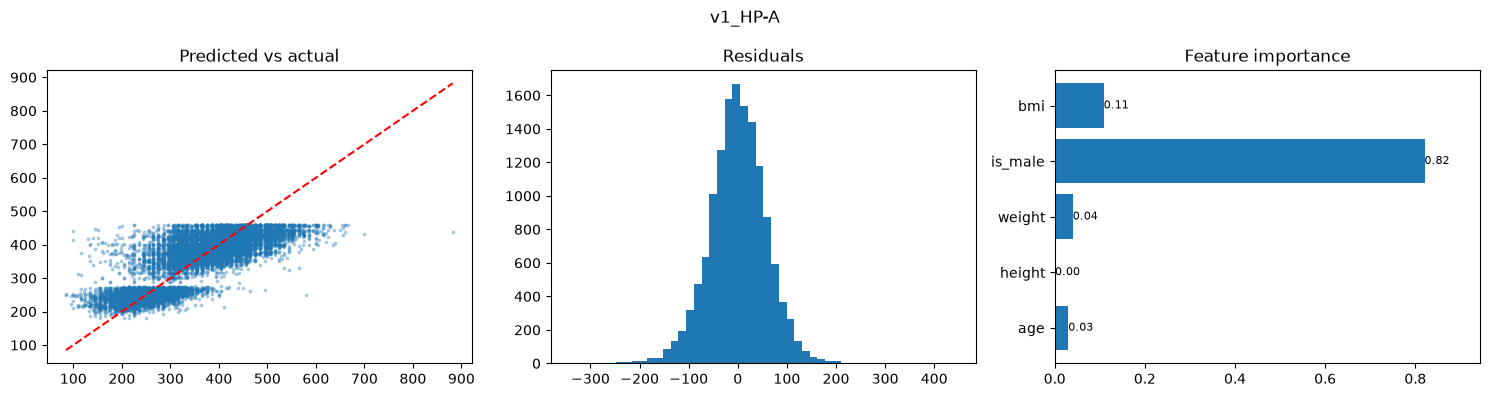

v1_HP-A rmse = 58.32 r2 = 0.632 emissions_kg = 1.2469466655192448e-06


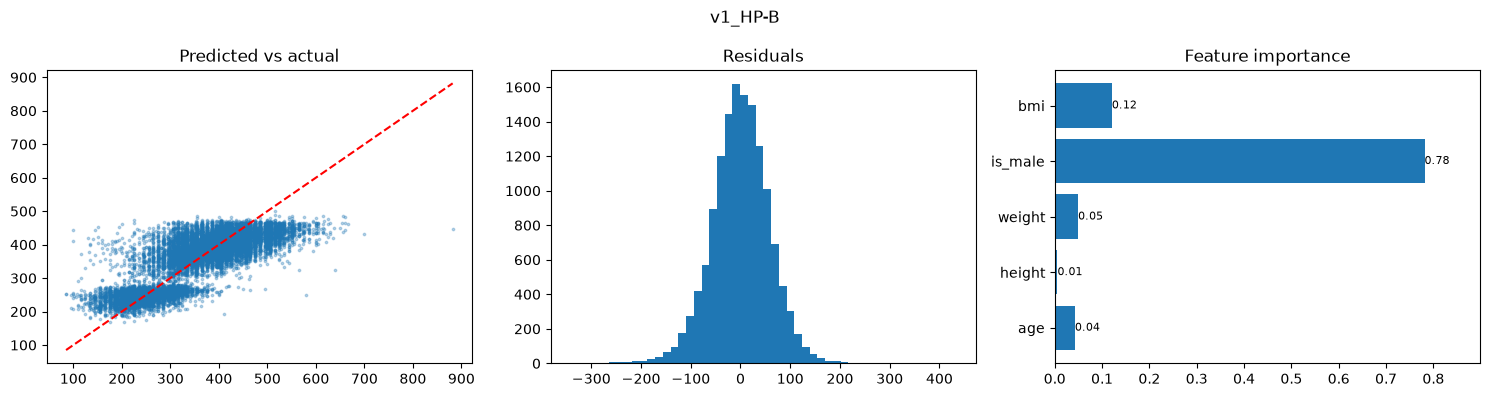

v1_HP-B rmse = 58.28 r2 = 0.632 emissions_kg = 3.9143358629710655e-06


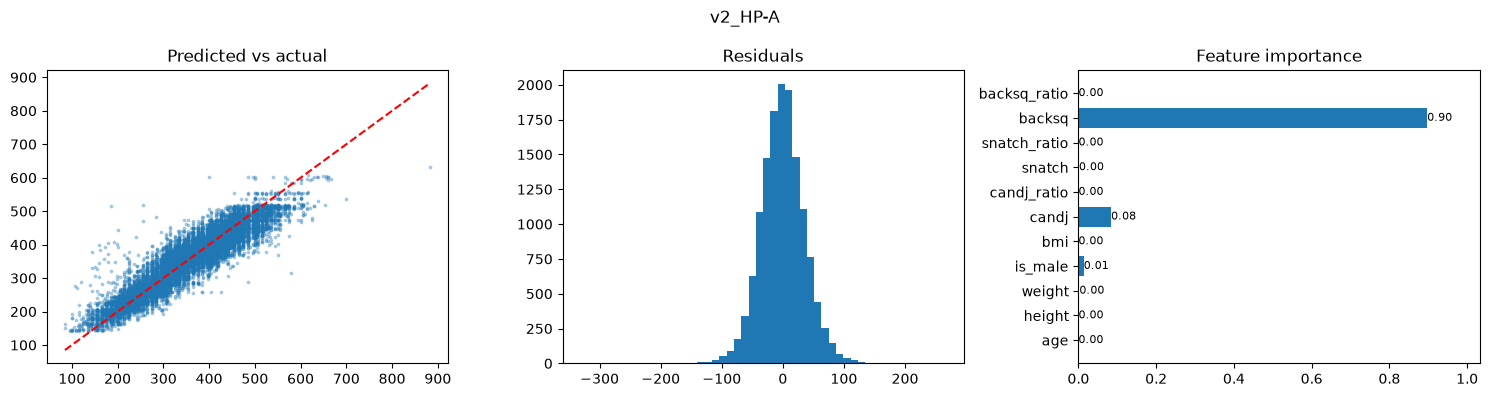

v2_HP-A rmse = 36.6 r2 = 0.855 emissions_kg = 3.868040288597524e-06


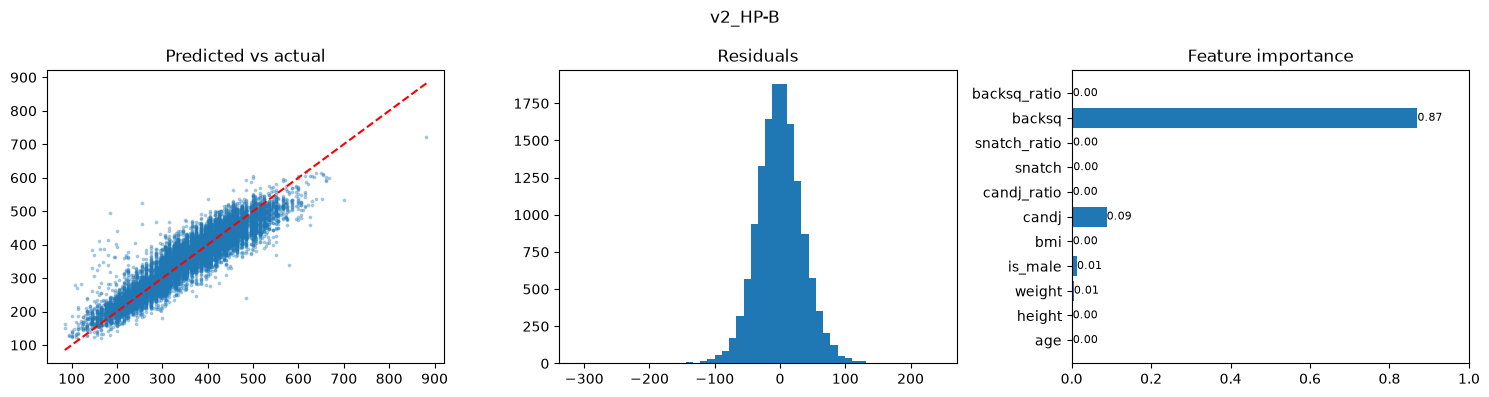

v2_HP-B rmse = 36.04 r2 = 0.859 emissions_kg = 1.0773854883046233e-05


In [29]:
hyperparams = {
    'HP-A': {'n_estimators': 50, 'max_depth': 6},
    'HP-B': {'n_estimators': 100, 'max_depth': 10},
}

mlflow.set_experiment('athletes-deadlift')

for version in ['v1', 'v2']:
    # get the features for this version from the feature store
    service = store.get_feature_service('athlete_service_' + version)
    data = store.get_historical_features(entity_df=labels, features=service).to_df()

    X = data.drop(columns=['athlete_id', 'event_timestamp', 'deadlift'])
    y = data['deadlift']
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    for hp_name, params in hyperparams.items():
        run_name = version + '_' + hp_name

        with mlflow.start_run(run_name=run_name):
            # measure the carbon emissions of the training
            tracker = OfflineEmissionsTracker(country_iso_code='USA', save_to_file=False, log_level='error')
            tracker.start()
            model = RandomForestRegressor(**params, random_state=42, n_jobs=-1)
            model.fit(X_train, y_train)
            emissions = tracker.stop()

            pred = model.predict(X_test)
            rmse = mean_squared_error(y_test, pred) ** 0.5
            mae = mean_absolute_error(y_test, pred)
            r2 = r2_score(y_test, pred)

            # three plots in one picture
            fig, ax = plt.subplots(1, 3, figsize=(15, 4))
            ax[0].scatter(y_test, pred, s=3, alpha=0.3)
            ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
            ax[0].set_title('Predicted vs actual')
            ax[1].hist(y_test - pred, bins=50)
            ax[1].set_title('Residuals')
            bars = ax[2].barh(X.columns, model.feature_importances_)
            ax[2].bar_label(bars, fmt='%.2f', fontsize=8)
            ax[2].margins(x=0.15)
            ax[2].set_title('Feature importance')
            fig.suptitle(run_name)
            plt.tight_layout()
            plt.show()

            mlflow.log_param('feature_version', version)
            mlflow.log_params(params)
            mlflow.log_metrics({'rmse': rmse, 'mae': mae, 'r2': r2, 'emissions_kg': emissions})

            print(run_name, 'rmse =', round(rmse, 2), 'r2 =', round(r2, 3), 'emissions_kg =', emissions)

## 5. Compare the results (metrics and carbon)

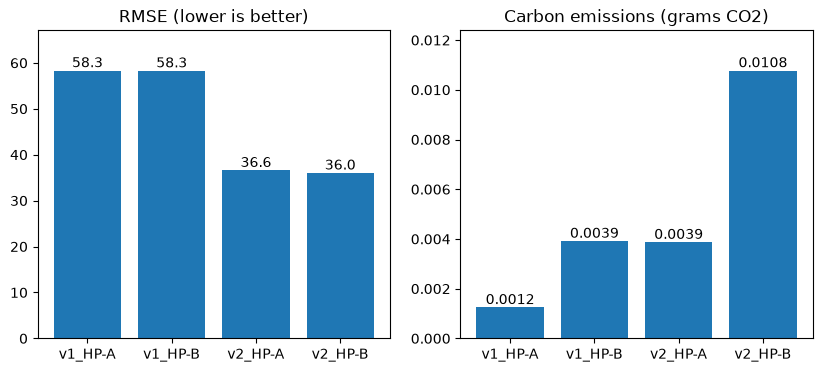

,run,rmse,mae,r2,emissions_kg
3,v1_HP-A,58.319297,44.882867,0.631933,0.000001
2,v1_HP-B,58.282525,44.928915,0.632397,0.000004
1,v2_HP-A,36.598227,27.879348,0.855049,0.000004
0,v2_HP-B,36.036972,27.466991,0.859460,0.000011


In [30]:
runs = mlflow.search_runs(experiment_names=['athletes-deadlift']).sort_values('start_time')
results = runs[['tags.mlflow.runName', 'metrics.rmse', 'metrics.mae', 'metrics.r2', 'metrics.emissions_kg']]
results.columns = ['run', 'rmse', 'mae', 'r2', 'emissions_kg']
results = results.drop_duplicates('run', keep='last').sort_values('run')   # keep the latest run of each

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
bars = ax[0].bar(results['run'], results['rmse'])
ax[0].bar_label(bars, fmt='%.1f')
ax[0].margins(y=0.15)
ax[0].set_title('RMSE (lower is better)')
bars = ax[1].bar(results['run'], results['emissions_kg'] * 1000)
ax[1].bar_label(bars, fmt='%.4f')
ax[1].margins(y=0.15)
ax[1].set_title('Carbon emissions (grams CO2)')
plt.show()

results

## 7. Conclusions
- The feature version matters most. v2 (with the other lifts) cuts the error a lot compared with v1.
- The bigger forest (HP-B) gives almost no improvement on v2 but uses several times more carbon.
- The carbon numbers are estimates, so they are best used to compare the runs with each other.